In [1]:
from __future__ import print_function, division
import OCRT
import importlib
importlib.reload(OCRT)
from OCRT import OCRT2D
import numpy as np

import tensorflow as tf
tf.compat.v1.disable_eager_execution()
import matplotlib.pyplot as plt
import numpy as np
from time import time
import scipy.io


In [2]:
max_angle = 180
interval = 6
n_bscans = int(max_angle/interval)*2+1
anglename = str(max_angle) + '-' + str(interval) + '-' + str(max_angle)

sample_id = 'mouse_vas_deferens1'  # a string that denotes which data to run
# sample_id = 'phantom'  # a string that denotes which data to run

data_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/Datasets/' + anglename + '/'  # where is the OCRT input data located?
save_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/' + anglename + '/'  # where to save the tf graph after optimization

data_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/data/'  # where is the OCRT input data located?
save_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/'  # where to save the tf graph after optimization


data loaded: 5.591243505477905 sec
Instructions for updating:
Use `tf.cast` instead.
Instructions for updating:
Use `tf.cast` instead.
Instructions for updating:
Use `tf.cast` instead.
INFO:tensorflow:Restoring parameters from c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/mouse_vas_deferens1/model.ckpt


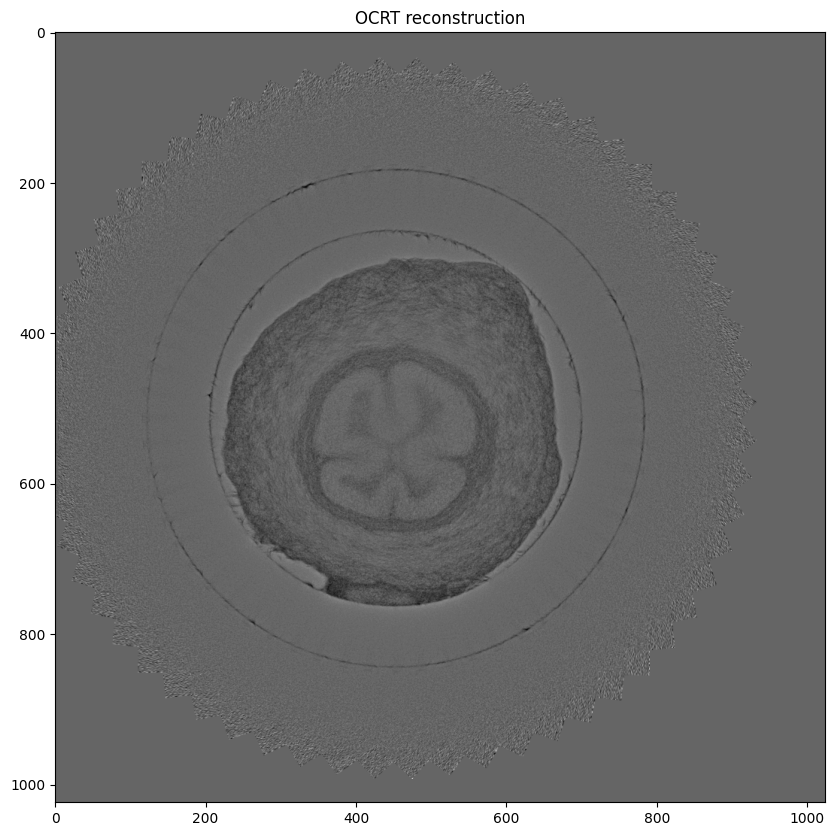

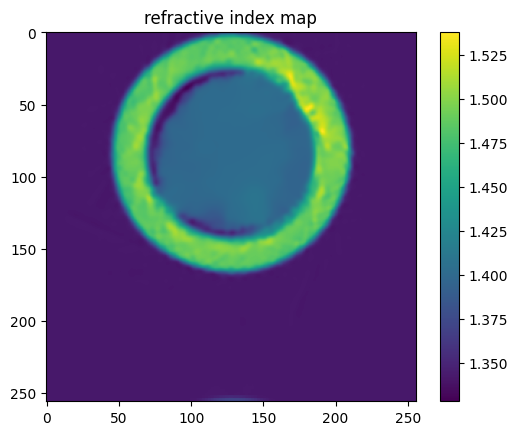

In [ ]:


a = OCRT2D(sample_id=sample_id,save_directory=save_directory)

a.sess = tf.compat.v1.InteractiveSession()

a.load_data_and_resolve_constants(data_directory=data_directory, max_angle = max_angle, angle_step = interval)
a.create_tf_variables()
a.create_losses()
a.sess.run( tf.compat.v1.global_variables_initializer())
a.saver =  tf.compat.v1.train.Saver()  # NOTE: saver only saves variables defined up until this line is run!
a.saver.restore(a.sess, a.save_directory + '/model.ckpt')

# recon = a.recon
recon = a.sess.run(a.recon, feed_dict=a.get_feed_dict())
recon = recon.sum(2)

plt.figure(figsize=(10, 10))
plt.imshow(recon, cmap='gray_r')
plt.title('OCRT reconstruction')
plt.show()

RI = a.sess.run(a.RI, feed_dict={a.xz_delta: np.zeros((n_bscans, 2))})  # remove xy_delta shifts
# RI = a.sess.run(a.RI, feed_dict={a.xz_delta: np.zeros((n_bscans-1, 2))})  # remove xy_delta shifts
        
plt.imshow(RI)
plt.title('refractive index map')
plt.colorbar()
plt.show()


In [5]:
filename = save_directory + sample_id + '_result.mat'
result = {}
result['recon'] = recon
result['RI'] = RI
scipy.io.savemat(filename, result)
